# Read in the Colombia COVID Data

In [1]:
import pandas as pd

# This overrides how Colab displays Pandas Series.
from google.colab import _reprs
_reprs.disable_pandas_series_repr()

url = "http://dlsun.github.io/pods/data/covid/"
df_CO = pd.read_csv(url + "colombia_2020-05-28.csv")
df_CO

,Departamento,Edad,Sexo,Tipo,Ubicación,Estado,Fecha de inicio de síntomas,Fecha de muerte,Fecha de diagnóstico,Fecha recuperado
0,Bogotá D.C.,19,F,Importado,Recuperado,Leve,2020-02-27,- -,2020-03-06,2020-03-13
1,Valle del Cauca,34,M,Importado,Recuperado,Leve,2020-03-04,- -,2020-03-09,2020-03-19
2,Antioquia,50,F,Importado,Recuperado,Leve,2020-02-29,- -,2020-03-09,2020-03-15
3,Antioquia,55,M,Relacionado,Recuperado,Leve,2020-03-06,- -,2020-03-11,2020-03-26
4,Antioquia,25,M,Relacionado,Recuperado,Leve,2020-03-08,- -,2020-03-11,2020-03-23
...,...,...,...,...,...,...,...,...,...,...
25361,Buenaventura D.E.,48,M,En estudio,Hospital,Moderado,2020-05-12,- -,2020-05-28,NaN
25362,Valle del Cauca,55,F,En estudio,Casa,Leve,2020-05-21,/ /,2020-05-28,NaN
25363,Buenaventura D.E.,39,F,En estudio,Casa,Leve,2020-05-23,/ /,2020-05-28,NaN
25364,Valle del Cauca,13,F,En estudio,Casa,Leve,2020-05-13,/ /,2020-05-28,NaN


# Visualizing Quantitative Data

<Axes: xlabel='age'>

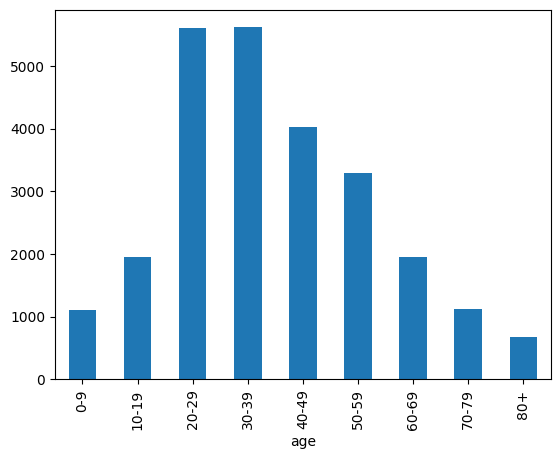

In [4]:
df_CO["age"] = pd.cut(
    df_CO["Edad"],
    bins=[0, 10, 20, 30, 40, 50, 60, 70, 80, 120],
    labels=["0-9", "10-19", "20-29", "30-39", "40-49", "50-59", "60-69", "70-79", "80+"],
    right=False)
df_CO["age"].value_counts(sort=False).plot.bar()

<Axes: ylabel='Frequency'>

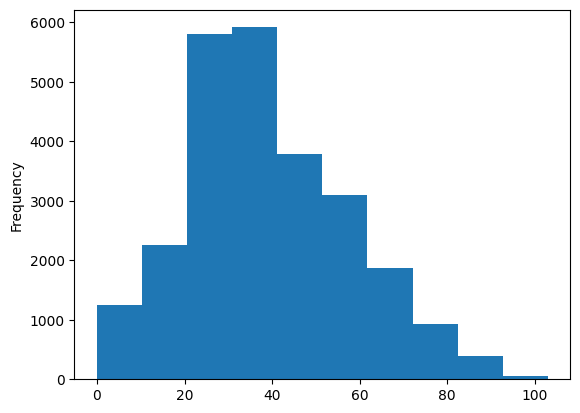

In [7]:
df_CO["Edad"].plot.hist()

# Summarizing Quantitative Data

### Summaries of Center: Mean

In [10]:
df_CO["Edad"].sum() / len(df_CO["Edad"])

np.float64(39.04742568792872)

In [11]:
df_CO["Edad"].mean()

np.float64(39.04742568792872)

The mean is the value $c$ that minimizes the sum of squared distances to the observations.

In [12]:
c = 50
((df_CO["Edad"] - c) ** 2).sum()

np.int64(11872105)

<Axes: >

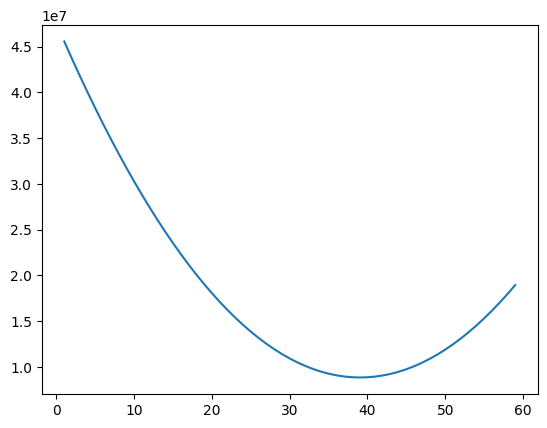

In [15]:
cs = range(1, 60)
sum_squared_distances = []

for c in cs:
  sum_squared_distances.append(((df_CO["Edad"] - c) ** 2).sum())

pd.Series(sum_squared_distances, index=cs).plot.line()

### Summaries of Center: Median

In [16]:
# calculate median manually
# code generated by ChatGPT

def calculate_median(series):
    sorted_series = sorted(series)
    length = len(sorted_series)

    if length % 2 == 0:
        # If the length is even, take the average of the middle two values
        middle_left = sorted_series[length // 2 - 1]
        middle_right = sorted_series[length // 2]
        median = (middle_left + middle_right) / 2
    else:
        # If the length is odd, take the middle value
        median = sorted_series[length // 2]

    return median

calculate_median(df_CO["Edad"])

37.0

In [17]:
# calculate median using built-in Pandas functions
df_CO["Edad"].median()

37.0

## Summaries of Spread

### Summaries of Spread: Variance

In [18]:
# calculate variance manually
(((df_CO["Edad"] - df_CO["Edad"].mean()) ** 2).sum() /
 (len(df_CO) - 1))

np.float64(348.0870469898451)

In [19]:
# calculate variance using built-in Pandas functions
df_CO["Edad"].var()

348.08704698984627

### Summaries of Spread: Standard Deviation

In [20]:
# calculate sd manually
import numpy as np
np.sqrt(df_CO["Edad"].var())

np.float64(18.657091064521452)

In [21]:
# calculate sd using built-in Pandas functions
df_CO["Edad"].std()

18.657091064521452